## This is some examples to use this package


In [56]:
import sys
sys.path.insert(0, "..")            # the package lives one folder up

import src                      # import Nbody before running anything in jax (CPU runtime setup)
from src import Integrator, Integrator_no_grad, State, get_default_ICs
from src.ics.initial_conditions import ElementsIC
from src.integrator.timing import calc_dtdelements
import jax
import numpy as np
import matplotlib.pyplot as plt
import logging
import time
print(jax.devices())

[CpuDevice(id=0)]


In [57]:
NAMES = list("bcdefgh")
COLORS = plt.cm.tab10(np.arange(7))

In [58]:
jax.config.update("jax_log_compiles", True)

logger = logging.getLogger("jax")
logger.setLevel(logging.WARNING)

for handler in logger.handlers[:]:
    logger.removeHandler(handler)

logger.propagate = False

handler = logging.FileHandler("jax_compile.log", mode="w")
handler.setFormatter(logging.Formatter("%(asctime)s %(message)s"))

logger.addHandler(handler)

### Compare the integrator and the jacfwd and jax.grad

In [59]:
from dataclasses import replace
tmax = 30.0
h = 0.1
ic = get_default_ICs("trappist-1")
s0 = State.from_ic(ic)
tt0 = src.create_transit_timing(tmax=tmax, ic=ic)
intr = Integrator_no_grad.default(h=h, t0=0.0, tmax=tmax)

def transit_times(m):
    """Masses (8,) -> transit times (8 bodies, ntt). Positions and velocities are kept fixed."""
    s = replace(s0, m=m)
    _, tt = intr(s, tt0)
    return tt.tt

t = time.perf_counter()
dt_dm = jax.jit(jax.jacfwd(transit_times))(s0.m)      # shape (8, ntt, 8): [planet, transit, mass of body]
jax.block_until_ready(dt_dm)
print(f"jacfwd (incl. compilation): {time.perf_counter() - t:.1f} s,  shape {dt_dm.shape}")

count = np.asarray(intr(s0, tt0)[1].count)
print("transits per planet:", count[1:])

jacfwd (incl. compilation): 16.9 s,  shape (8, 23, 8)
transits per planet: [20 13  7  4  3  2  2]


In [60]:
intr_grad = Integrator.default(h=h, t0=0.0, tmax=tmax)
t = time.perf_counter()
s_grad, tt_grad = intr_grad(State.from_ic(ic), tt0)
jax.block_until_ready((s_grad,tt_grad))

print(f"Integrator here (incl. compilation): {time.perf_counter() - t:.1f} s")
count = tt_grad.count
print("transits per planet:", count[1:])

dt_dm_pkg = np.asarray(tt_grad.dtdq0)[:, :, 6, :]        # (8, ntt, 8)

worst = 0.0
for p in range(1, 8):
    a = np.asarray(dt_dm)[p, :count[p]]
    b = dt_dm_pkg[p, :count[p]]
    worst = max(worst, np.max(np.abs(a - b)) / np.max(np.abs(b)))
print(f"max relative difference, jacfwd vs package: {worst:.1e}")

Integrator here (incl. compilation): 0.1 s
transits per planet: [20 13  7  4  3  2  2]
max relative difference, jacfwd vs package: 5.7e-13


### Runtime after compiled

In [61]:
ic = get_default_ICs("trappist-1")
s = State.from_ic(ic)
tmax = 1000.0 # max time (day) 


In [62]:
ic = get_default_ICs("trappist-1")

s = State.from_ic(ic)
tt = src.create_transit_timing(tmax=tmax,ic=ic)
Intr = Integrator_no_grad.default(h=0.1,t0=0.0,tmax=tmax,)

start = time.perf_counter()
s, tt = Intr(s, tt)
jax.block_until_ready(s)
jax.block_until_ready(tt)
print("Total time for Integrator without grad for the first time:", time.perf_counter() - start)

Total time for Integrator without grad for the first time: 0.24003402300877497


In [63]:
ic = get_default_ICs("trappist-1")
Intr = Integrator_no_grad.default(h=0.1, t0=0.0, tmax=tmax)

for i in range(3):
    s = State.from_ic(ic)
    tt = src.create_transit_timing( tmax=tmax, ic=ic)
    start = time.perf_counter()
    s, tt = Intr(s, tt)
    jax.block_until_ready(s)
    jax.block_until_ready(tt)
    end = time.perf_counter()
    print(f"ReRun -Intergator without grad: {i+1}: {end-start:.4f} s")

ReRun -Intergator without grad: 1: 0.2431 s
ReRun -Intergator without grad: 2: 0.2409 s
ReRun -Intergator without grad: 3: 0.2391 s


### With grad

In [64]:
ic = get_default_ICs("trappist-1")
s = State.from_ic(ic)

In [65]:
t0 = 0.0        # Initial time
h = 0.1         # Time step
tt = src.create_transit_timing(tmax = tmax, ic = ic,)

#with grad
Intr = Integrator.default(h = h, t0 = t0, tmax = tmax)
start = time.perf_counter()
s,tt = Intr(s, tt)
jax.block_until_ready(s)
jax.block_until_ready(tt)
end = time.perf_counter()
print(f'Total time for Integrator without grad for the first time: {end - start:.4f} seconds!')

Total time for Integrator without grad for the first time: 1.6767 seconds!


In [66]:
ic = get_default_ICs("trappist-1")

Intr = Integrator.default(h=0.1, t0=0.0, tmax=tmax)

for i in range(3):
    s = State.from_ic(ic)
    tt = src.create_transit_timing( tmax=tmax, ic=ic)
    start = time.perf_counter()
    s, tt = Intr(s, tt)
    jax.block_until_ready(s)
    jax.block_until_ready(tt)
    end = time.perf_counter()
    print(f"ReRun - Integrator with grad calculated/recorded - {i+1}: {end-start:.4f} s")                     

ReRun - Integrator with grad calculated/recorded - 1: 1.6760 s
ReRun - Integrator with grad calculated/recorded - 2: 1.6690 s
ReRun - Integrator with grad calculated/recorded - 3: 1.6738 s


In [67]:
print('count:', tt.count)
print('tt:', tt.tt)
print('ntt:', tt.ntt)
print('gsave: ', tt.gsave)


count: [  0 662 413 247 163 109  81  54]
tt: [[ 0.          0.          0.         ...  0.          0.
   0.        ]
 [ 0.79053962  2.30223396  3.81326796 ...  0.          0.
   0.        ]
 [ 0.45349103  2.87488048  5.29674126 ...  0.          0.
   0.        ]
 ...
 [ 2.64920503 11.85743305 21.06523851 ...  0.          0.
   0.        ]
 [ 5.87594408 18.2273673  30.57983533 ...  0.          0.
   0.        ]
 [ 0.64619779 19.37745733 38.11249612 ...  0.          0.
   0.        ]]
ntt: 665
gsave:  [ 0.00000000e+00  6.54022648e-08 -1.89322982e-04 -7.19096213e-05
 -6.22483636e-04 -2.53470160e-03 -1.38846304e-03 -2.50025855e-03]


### Plot the tranist timing

In [68]:
TOFF = 7300.0
d = np.genfromtxt('./Examples/T1_timings_20191203.txt', delimiter= ',')
planet = d[:, 0].astype(int)
epoch  = d[:, 1].astype(int)
tobs   = d[:, 2] - TOFF
terr   = d[:, 3]
print(f"{len(d)} transits:", {NAMES[p-1]: int((planet == p).sum()) for p in range(1, 8)})
print(f"time span: {d[:,2].min():.1f} to {d[:,2].max():.1f}  (BJD − 2450000), as Agol")

447 transits: {'b': 161, 'c': 107, 'd': 53, 'e': 49, 'f': 33, 'g': 30, 'h': 14}
time span: 7282.8 to 8785.4  (BJD − 2450000), as Agol


In [69]:
base = get_default_ICs("trappist-1")
H = np.asarray(base.epsilon)                       # hierarchy matrix
el_default = np.array(base.elements)
el_default[1:, 2] -= TOFF

t0   = 7257.93115525 - TOFF - 0.5                  # start before the first transit
tmax = 8790.0 - TOFF - t0                          # integrate past the last observed transit
h    = 0.0600

print(f"Current integration time: {tmax:2f}, and the time step is {h: 4f}.")
intr = Integrator.default(h=h, t0=t0, tmax=tmax)
Intr_no_grad = Integrator_no_grad.default(h=h, t0=t0, tmax=tmax)
tt_template = src.create_transit_timing(tmax=tmax, ic=ElementsIC(t0, H, el_default))

FREE = [0, 1, 2, 3, 4]                         # fit m, P, t0, e cosω, e sinω of each planet (ElementsIC index)
JCOL = {0: 6, 1: 0, 2: 1, 3: 2, 4: 3}          # dtdelements element axis

def model_grad(el):
    """Transit times (n, ntt), counts (n,) and d(times)/d(elements) (n, ntt, 7, n)."""
    ic = ElementsIC(t0, H, el)
    s, tt = intr(State.from_ic(ic), tt_template)
    tt = calc_dtdelements(s, tt)
    return np.asarray(tt.tt), np.asarray(tt.count), np.asarray(tt.dtdelements)

def model_no_grad(el):
    """Transit times (n, ntt), counts (n,) and d(times)/d(elements) (n, ntt, 7, n)."""
    ic = ElementsIC(t0, H, el)
    s, tt = Intr_no_grad(State.from_ic(ic), tt_template)
    return np.asarray(tt.tt), np.asarray(tt.count)

start = time.perf_counter()
T_def, C_def, _ = model_grad(el_default)
print(f"first call (includes compilation): {time.perf_counter() - start:.1f} s")
start = time.perf_counter()
T_def, C_def, _ = model_grad(el_default)
print(f"second call: {time.perf_counter() - start:.1f} s. Does it become smaller?")
print(f"transits per planet: {C_def[1:]}")

Current integration time: 1532.568845, and the time step is  0.060000.
first call (includes compilation): 3.9 s
second call: 3.9 s. Does it become smaller?
transits per planet: [1015  633  378  252  166  125   82]


In [70]:
offset = {}
for p in range(1, 8):
    sel = planet == p
    nearest = np.array([np.argmin(np.abs(T_def[p, :C_def[p]] - t)) for t in tobs[sel]])
    offset[p] = int(np.round(np.median(nearest - epoch[sel])))
k = epoch + np.array([offset[p] for p in planet])       # model transit index of each observation
print("epoch offsets:", offset)
print(k.shape)

epoch offsets: {1: 43, 2: 10, 3: 74, 4: 9, 5: 6, 6: 3, 7: 21}
(447,)


### Results from default elements vs data 20191203

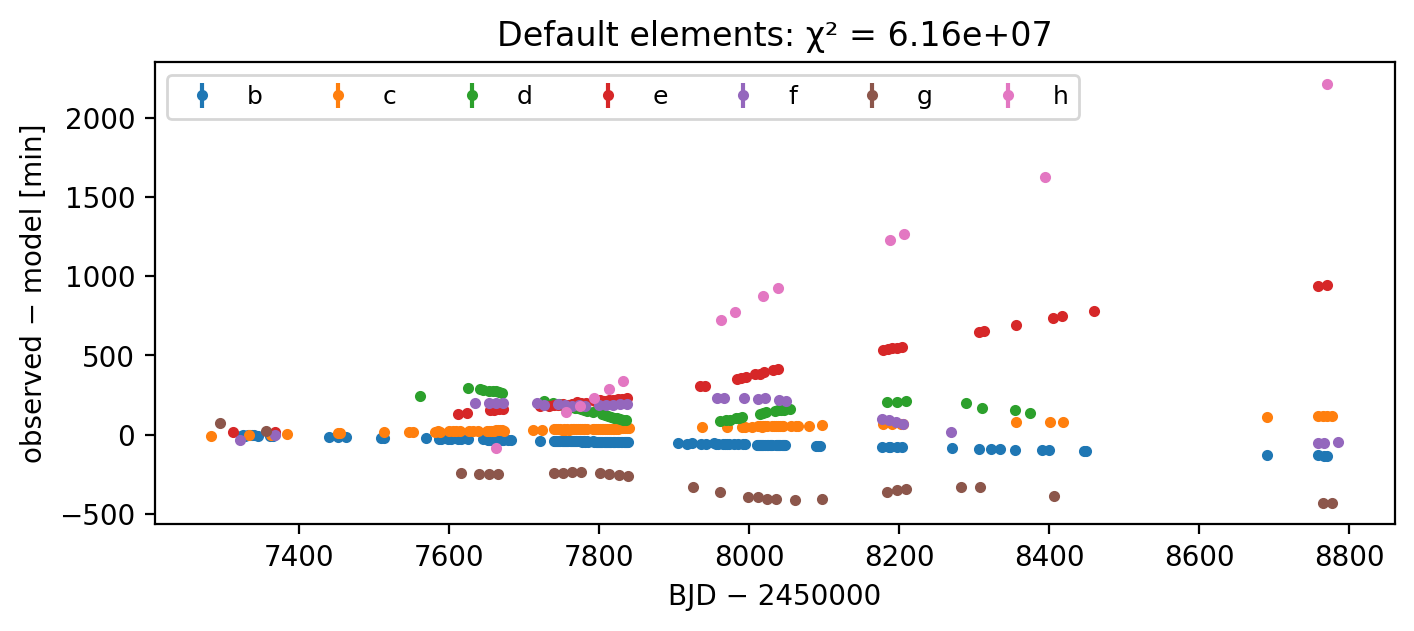

In [71]:
res_def = (tobs - T_def[planet, k]) * 1440            # minutes
fig, ax = plt.subplots(figsize=(8, 3), dpi = 200)
for p in range(1, 8):
    sel = planet == p
    ax.errorbar(tobs[sel] + TOFF, res_def[sel], terr[sel] * 1440, fmt="o", ms=3, color=COLORS[p-1], label=NAMES[p-1])
ax.set(xlabel="BJD − 2450000", ylabel="observed − model [min]",
       title=f"Default elements: χ² = {np.sum((res_def / (terr * 1440))**2):.3g}")
ax.legend(ncol=7, fontsize=9)
plt.show()

### Gradient descent and minimization

In [72]:
def residuals_only(el):
    T, C = model_no_grad(el)
    if not np.all(k < C[planet]):
        return None
    r = (tobs - T[planet, k]) / terr
    return np.asarray(r)


def residuals_and_jacobian(el):
    T, C, D = model_grad(el)
    if not np.all(k < C[planet]):
        return None, None
    r = (tobs - T[planet, k]) / terr
    J = np.stack([D[planet, k, JCOL[e], b] for b in range(1, 8) for e in FREE], axis=1) / terr[:, None]
    return np.asarray(r), np.asarray(J)

def update(el, dp):
    el = el.copy()
    el[1:, FREE] += dp.reshape(7, len(FREE))
    return el

el = el_default.copy()
lam = 1e-3
r, J = residuals_and_jacobian(el)
chi2 = r @ r
history = [chi2]
print(f"iter 0: chi2 = {chi2:.6g}")
start = time.perf_counter()
init_start = start
# Levenberg-Marquardt algorithm
for it in range(1, 30):
    A, g = J.T @ J, J.T @ r
    while True:
        dp = np.linalg.solve(A + lam * np.diag(np.diag(A)), g)
        el_try = update(el, dp)
        r_try, J_try = residuals_and_jacobian(el_try)
        chi2_try = np.inf if r_try is None else r_try @ r_try
        if chi2_try < chi2 or lam > 1e8:
            break
        lam *= 10
    if chi2_try >= chi2:
        break
    converged = chi2 - chi2_try < 1e-4 * chi2
    el, r, J, chi2, lam = el_try, r_try, J_try, chi2_try, lam / 10
    history.append(chi2)
    print(f"iter {it}: chi2 = {chi2:.6g}, with time {time.perf_counter() - start: 1f} seconds")
    start = time.perf_counter()
    if converged:
        break

print(f"fit time {time.perf_counter() - init_start:.1f} s;  chi2 = {chi2:.1f} for {len(r)} transits, {J.shape[1]} parameters ")

cov = np.linalg.inv(J.T @ J)                        # Fisher-matrix covariance at the best fit
sigma = np.sqrt(np.diag(cov)).reshape(7, len(FREE))
el_fit = el

iter 0: chi2 = 6.15935e+07
iter 1: chi2 = 3.30022e+06, with time  3.919566 seconds
iter 2: chi2 = 953358, with time  3.917519 seconds
iter 3: chi2 = 442994, with time  11.799217 seconds
iter 4: chi2 = 368034, with time  3.892157 seconds
iter 5: chi2 = 50322.4, with time  3.895805 seconds
iter 6: chi2 = 21732.3, with time  3.931781 seconds
iter 7: chi2 = 700.499, with time  3.900473 seconds
iter 8: chi2 = 654.82, with time  3.916412 seconds
iter 9: chi2 = 654.343, with time  3.917250 seconds
iter 10: chi2 = 654.343, with time  3.908022 seconds
fit time 47.0 s;  chi2 = 654.3 for 447 transits, 35 parameters 


In [73]:
print(el)

[[ 1.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 4.68795425e-05  1.51078371e+00 -4.24496120e+01 -5.38262240e-03
   1.34038331e-03  1.57079633e+00  0.00000000e+00]
 [ 4.21081701e-05  2.42206713e+00 -4.14128959e+01 -1.70822769e-03
  -1.68435044e-03  1.57079633e+00  0.00000000e+00]
 [ 1.28370562e-05  4.04971541e+00 -4.29321767e+01 -6.32697064e-03
   1.99393726e-03  1.57079633e+00  0.00000000e+00]
 [ 2.33504254e-05  6.09994172e+00 -4.21724387e+01  3.21263615e-03
  -5.03984218e-03  1.57079633e+00  0.00000000e+00]
 [ 3.50281174e-05  9.20927422e+00 -4.29265774e+01 -9.34773919e-03
  -1.23464851e-03  1.57079633e+00  0.00000000e+00]
 [ 4.43311485e-05  1.23512232e+01 -4.22848220e+01  2.92867476e-03
   8.34851426e-04  1.57079633e+00  0.00000000e+00]
 [ 1.12627334e-05  1.87724973e+01 -5.03916984e+01 -4.04561859e-03
  -3.66540581e-04  1.57079633e+00  0.00000000e+00]]


### Transit-timing variations

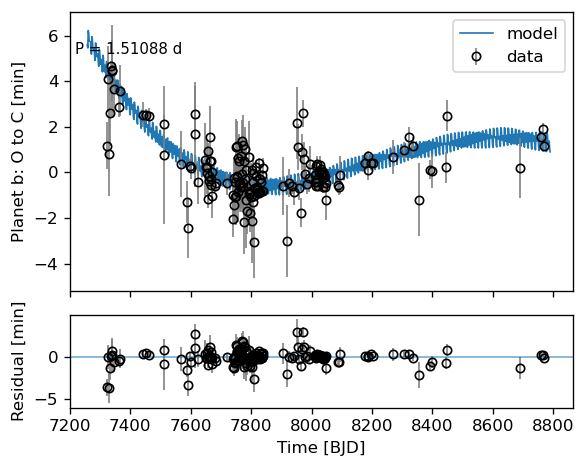

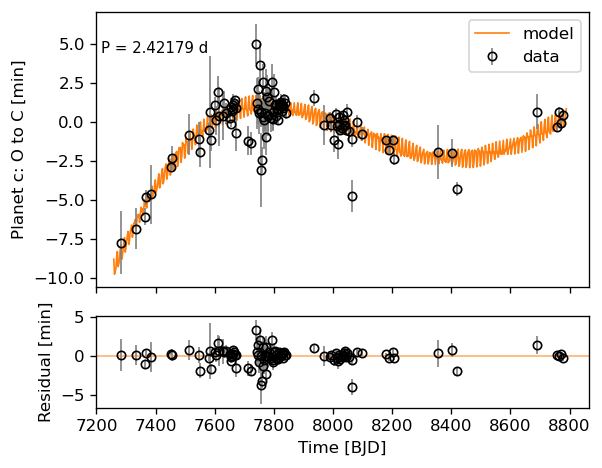

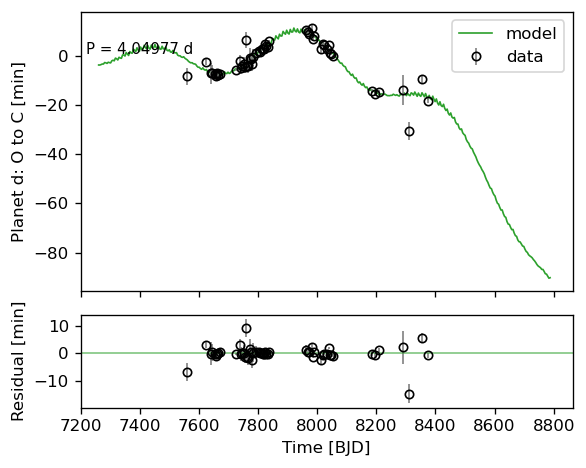

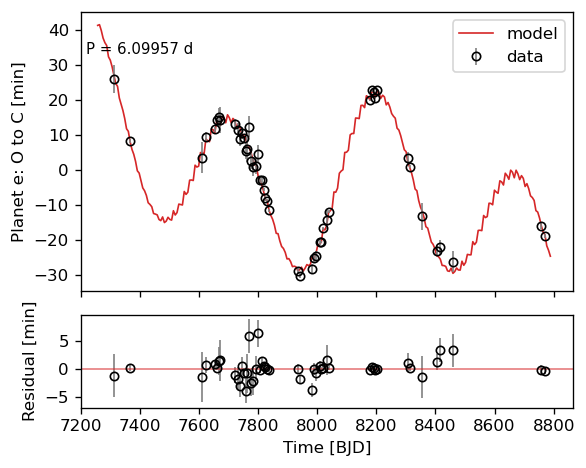

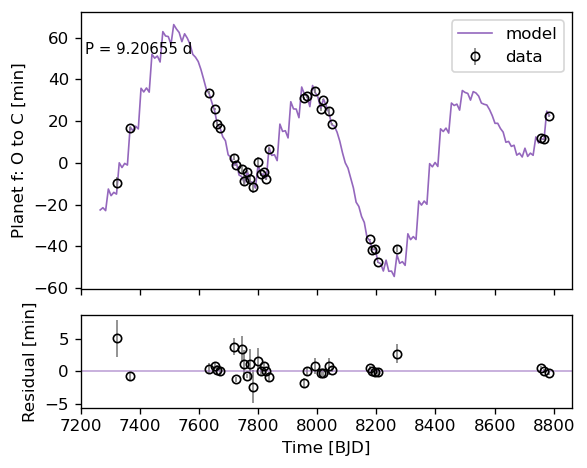

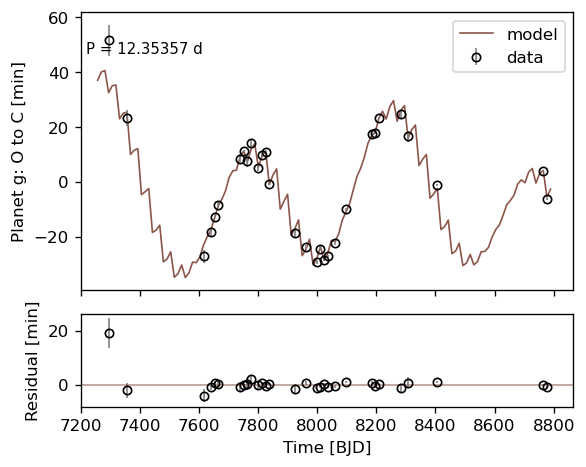

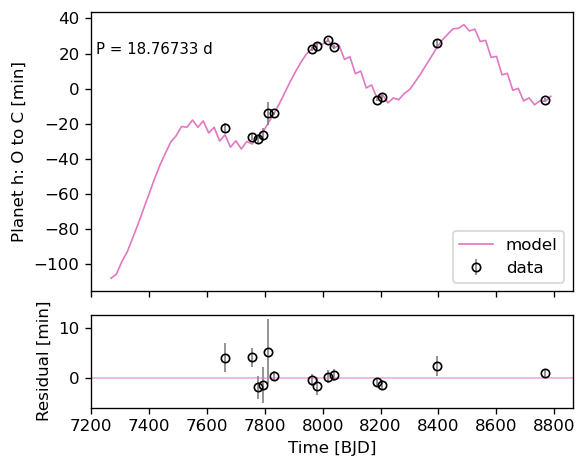

In [74]:
T_fit, C_fit, _ = model_grad(el_fit)
res_fit = (tobs - T_fit[planet, k]) * 1440
for p in range(1, 8):
    fig, (ax1, ax2) = plt.subplots(2,1, figsize = (5, 4),dpi = 120, sharex = True, gridspec_kw= {'height_ratios': [3,1]})

    sel = planet == p
    w = 1 / terr[sel]**2
    P_lin, T0_lin = np.polyfit(k[sel], tobs[sel], 1, w=np.sqrt(w)) #orbital period and reference transit time, T = T0 + Pn
    n_all = np.arange(C_fit[p])
    n_all = n_all[T_fit[p, n_all] + TOFF >= 7200]

    ax1.plot(T_fit[p, n_all] + TOFF, (T_fit[p, n_all] - (T0_lin + P_lin * n_all)) * 1440, "-", color=COLORS[p-1], lw=1, label = 'model')
    ax1.errorbar(tobs[sel] + TOFF, (tobs[sel] - (T0_lin + P_lin * k[sel])) * 1440, terr[sel] * 1440,
                fmt="o", ms=5, color="k", ecolor="0.5", lw=1, label = 'data', mfc='none')
    ax1.set_ylabel(f"Planet {NAMES[p-1]}: O to C [min]")
    ax1.set_xlim(left = 7200)
    ax1.text(0.01, 0.85, f"P = {P_lin:.5f} d", transform=ax1.transAxes, fontsize=9)
    ax1.legend()

    ax2.errorbar(tobs[sel] + TOFF, res_fit[sel], terr[sel] * 1440, fmt="o", ms=5, color='k',ecolor="0.5", mfc='none', lw=1,label=NAMES[p-1])
    ax2.axhline(0, c = COLORS[p-1], lw = 1, alpha = 0.6)
    ax2.set_ylabel("Residual [min]")
    ax2.set_xlabel("Time [BJD]")
    
    plt.tight_layout()
    plt.show()

### Polynomial fit
An orders between 5 and 30

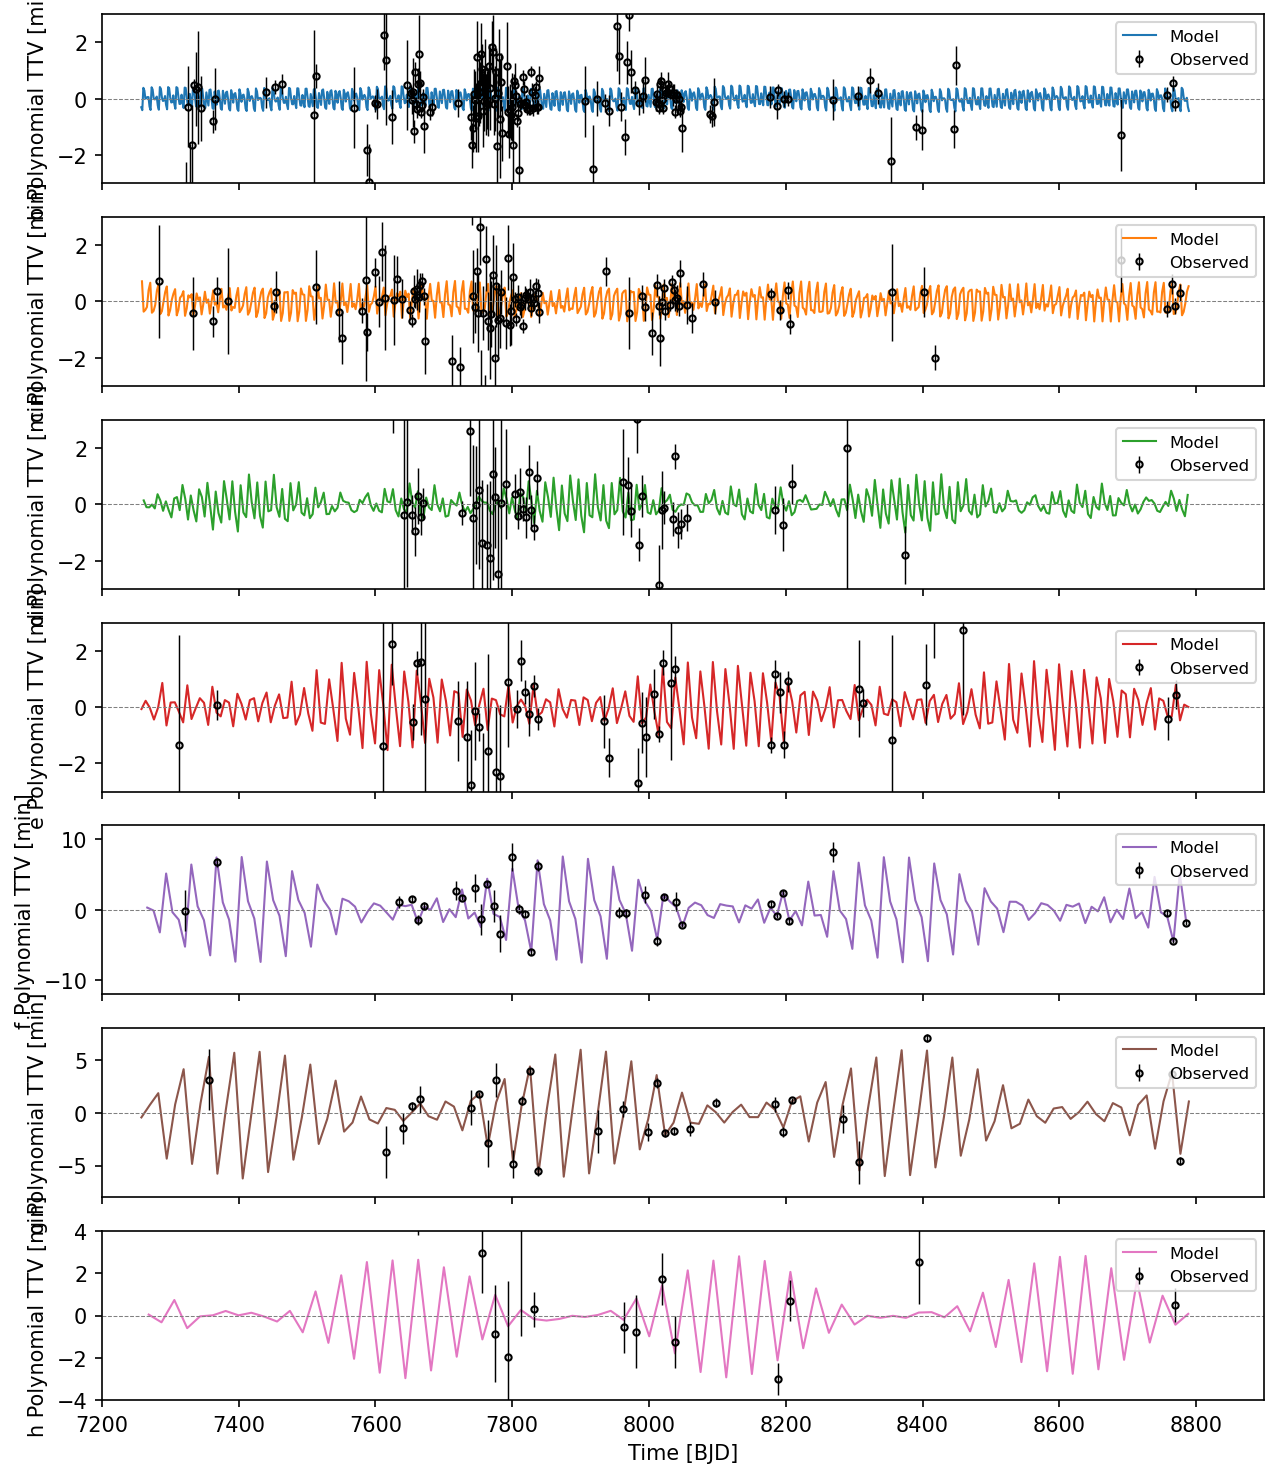

In [75]:
fig, axs = plt.subplots(7, 1, figsize=(10,12), dpi = 150, sharex= True)

ORD = [5, 5, 18, 30, 18, 18, 18] # ...I guess it requires different tryouts.
YRANGE = [3.0, 3.0, 3.0, 3.0, 12.0, 8.0, 4.0]

for p in range(1,8):
    ax = axs[p-1]
    sel = planet == p
    w = 1 / terr[sel]
    P_obs, T0_obs = np.polyfit(k[sel], tobs[sel], 1, w=w) #orbital period and reference transit time, T = T0 + Pn
 
    n_all = np.arange(C_fit[p])
    n_all = n_all[T_fit[p, n_all] + TOFF >= 7200]
    t_model = T_fit[p, n_all]
    epoch_model = np.rint((t_model - T0_obs) / P_obs).astype(int)

    poly = np.polynomial.Polynomial.fit(epoch_model,t_model,deg=ORD[p-1])

    ttv_model = (t_model - poly(epoch_model)) * 1440
    ttv_obs = (tobs[sel] - poly(k[sel])) * 1440

    sigma = terr[sel] * 1440

    ax.plot(t_model + TOFF, ttv_model, color=COLORS[p-1], lw=1.0, label="Model")
    ax.errorbar(tobs[sel] + TOFF, ttv_obs, yerr=sigma, fmt="o", ms=3,
                 color="k", ecolor="k", lw=0.7, mfc="none", label="Observed")
    ax.axhline(0, color="gray", lw=0.5, ls="--")

    ax.set_ylabel(f"{NAMES[p-1]} Polynomial TTV [min]")
    ax.set_ylim(-YRANGE[p-1], YRANGE[p-1])
    ax.set_xlim(7200, 8900)

    ax.legend(fontsize=8, loc="upper right")

axs[-1].set_xlabel('Time [BJD]')
plt.show()

### Likelihood profiling

In [76]:
PARAM_INDEX = {(p, e): (p - 1) * len(FREE) + j for p in range(1, 8) for j, e in enumerate(FREE)}
NPAR = 7 * len(FREE) #35

In [77]:
def lm_fit_fixed(el_init,fixed=None,max_iter=30,lam_init=1e-3,tol=1e-6,max_trials=20, verbose=False):
    """
    Levenberg-Marquardt optimization with fixed parameters.

    Uses:
        model_grad: Jacobian calculation
        model_no_grad: trial step evaluation
    Returns:
        el_best, chi2_best, success
    """

    el = el_init.copy()
    fixed = {} if fixed is None else fixed

    for (p, e), value in fixed.items():
        el[p, e] = value

    fixed_cols = {PARAM_INDEX[(p, e)] for p, e in fixed}
    free_cols = np.array([i for i in range(NPAR) if i not in fixed_cols], dtype=int)

    lam = lam_init

    start = time.perf_counter()
    r, J_full = residuals_and_jacobian(el)
    if r is None:
        return el, np.inf, False

    chi2 = float(r @ r)

    if verbose:
        print(f"Initial chi2 = {chi2:.6f}")

    for it in range(max_iter):

        J = J_full[:, free_cols]
        A = J.T @ J
        g = J.T @ r
        diag = np.maximum(np.diag(A), 1e-12)

        accepted = False

        for trial in range(max_trials):

            H = A + lam * np.diag(diag)
            try:
                dp_free = np.linalg.solve(H, g)

            except np.linalg.LinAlgError:
                lam *= 10
                continue

            dp = np.zeros(NPAR)
            dp[free_cols] = dp_free

            el_try = update(el, dp)

            # Keep selected parameters fixed
            for (p, e), value in fixed.items():
                el_try[p, e] = value

            # ONLY calculate residuals
            r_try = residuals_only(el_try)

            if r_try is None:
                lam *= 10
                continue

            chi2_try = float(r_try @ r_try)

            if (np.isfinite(chi2_try) and chi2_try < chi2):
                accepted = True
                break
            lam *= 10

        if not accepted:
            grad_norm = np.linalg.norm(g,ord=np.inf)
            if verbose:
                print(f"Iteration {it}: no accepted step, gradient norm = {grad_norm:.3e}")

            return el, chi2, grad_norm < 1e-6


        improvement = chi2 - chi2_try

        el = el_try
        r, J_full = residuals_and_jacobian(el)

        if r is None:
            return el, np.inf, False

        chi2 = float(r @ r)

        lam = max(lam / 10, 1e-12)

        if verbose:
            print(
                f"Iteration {it+1:2d}: "
                f"chi2 = {chi2:.6f}, "
                f"lambda = {lam:.2e}, "
                f"time = {time.perf_counter()-start:.1f}s"
            )

        if improvement < tol * max(chi2, 1.0):
            if verbose:
                print(f"Converged in {it+1} iterations." )
            return el, chi2, True

    return el, chi2, False

In [78]:
r_best, J_best = residuals_and_jacobian(el_fit)
chi2_min = r_best @ r_best
cov = np.linalg.pinv(J_best.T @ J_best)

print("Best-fit chi2:", chi2_min)
print("Number of parameters:", NPAR)
print("Jacobian rank:", np.linalg.matrix_rank(J_best))

Best-fit chi2: 654.3427824395817
Number of parameters: 35
Jacobian rank: 35


In [79]:
def likelihood_profile(el_best, planet_id, element_id, grid, verbose=True):
    """
    Profile likelihood for one orbital parameter.
    el_best: fit element
    planet_id: [1,8]
    element_id: Free[0-5]
    grid: base on Gaussian distribution

    return chi2, elements
    """

    chi2_grid = np.full(len(grid), np.nan)

    el_grid = []

    # Warm-start from the best fit
    el_current = el_best.copy()

    for i, value in enumerate(grid):

        fixed = {(planet_id, element_id): value}

        el_result, chi2, success = lm_fit_fixed(el_current, fixed=fixed,max_iter=30)

        if success:
            chi2_grid[i] = chi2
            el_current = el_result.copy()

        el_grid.append(el_result.copy())

        if verbose:
            print(
                f"{i+1}/{len(grid)} | "
                f"value={value:.6e} | "
                f"chi2={chi2:.6f} | "
                f"success={success}"
            )

    return chi2_grid, el_grid

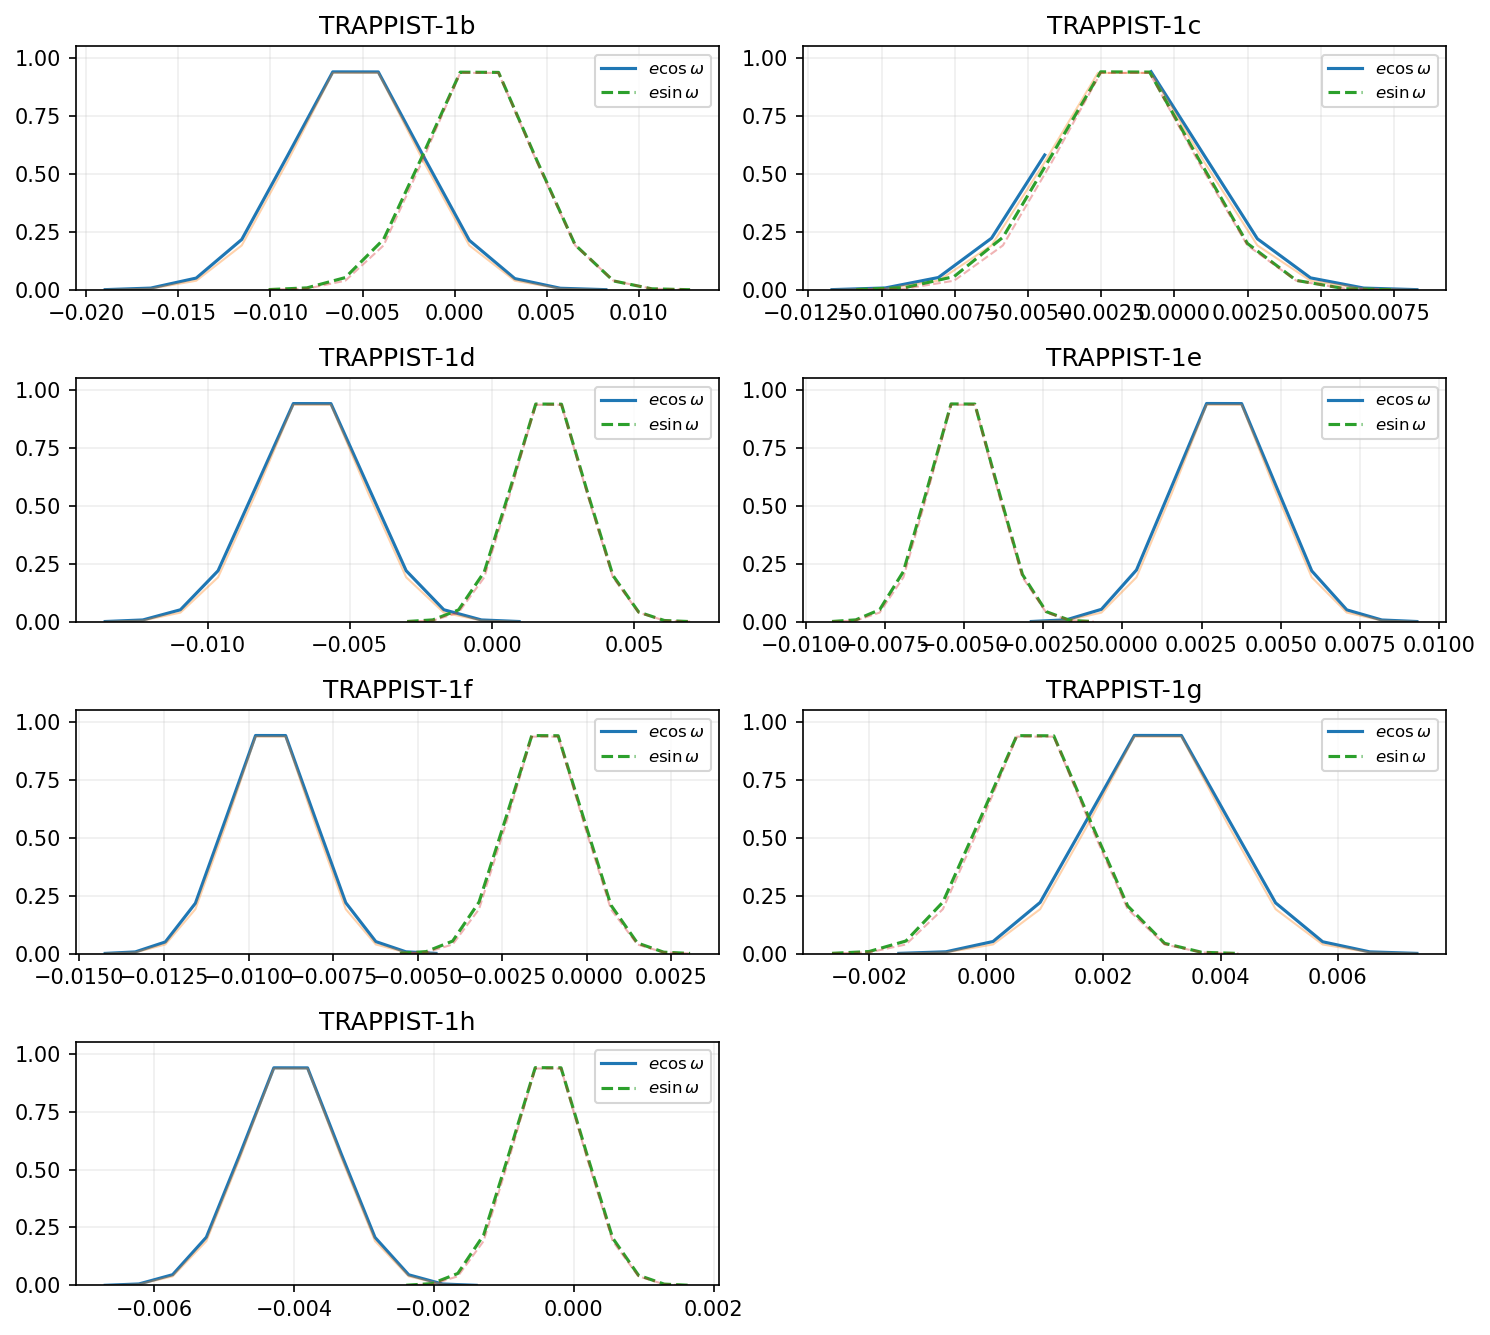

In [ ]:
fig, axs = plt.subplots(4, 2, figsize=(10, 9), dpi=150)

axs = axs.ravel()

for p in range(1, 8):

    ax = axs[p-1]

    for e, label, ls in [(FREE[3], r"$e\cos\omega$", "-"), (FREE[4], r"$e\sin\omega$", "--")]:

        idx = PARAM_INDEX[(p, e)]

        mu = el_fit[p, e]
        sigma = np.sqrt(cov[idx, idx])
        grid = np.linspace(mu - 4*sigma,  mu + 4*sigma, 12)
        chi2_grid, _ = likelihood_profile(el_fit,p,e,grid,verbose=False)

        L = np.exp(-0.5 * (chi2_grid - chi2_min))
        grid_gauss = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 300)
        L_gauss = np.exp( -0.5 * ((grid_gauss-mu)/sigma)**2)

        ax.plot(grid, L, ls=ls, lw=1.5,label=label)
        ax.plot(grid, L_gauss, ls=ls, lw=1, alpha=0.35)

    ax.set_title(f"TRAPPIST-1{NAMES[p-1]}")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

axs[-1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
delta_chi2 = chi2_grid - chi2_min

delta_chi2_gauss = ((grid - mu) / sigma)**2

print("Profile Δχ²:", delta_chi2)
print("Gaussian Δχ²:", delta_chi2_gauss)
print("Difference:",np.nanmax(np.abs(delta_chi2 - delta_chi2_gauss)))

Profile Δχ²: [14.32637563  9.69862697  5.92883323  3.05436728  1.10931432  0.12414797
  0.12550654  1.13606672  3.17450858  6.25554463 10.39001083 15.58501344]
Gaussian Δχ²: [16.         10.7107438   6.47933884  3.30578512  1.19008264  0.1322314
  0.1322314   1.19008264  3.30578512  6.47933884 10.7107438  16.        ]
Difference: 1.6736243745272077
